<a href="https://colab.research.google.com/github/chenharry66/adversial-audio-experiments/blob/main/universal_perturbation_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Setup

In [1]:
#install depencies
!pip install werpy scipy
!pip install --upgrade "numba==0.68.0"
!pip install librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 30.7 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [werpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 16.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 47.0 MB/s  0:00:01
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.44.0
    Uninstalling llvmlite-0.44.0:
      Successfully uninstalled llvmlite-0.44.0
  Attempting uninstall: numba
    Found existing installation: numba 0.61.2
    Uninstalling numba-0.61.2:
      Successfully uninstalled numba-0.61.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [numba]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.38.3 requires numba<=0.65.1,>=0.58, but you have numba 0.68.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.68.0 which is incompatible.


##Model Definition and Helper Functions

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [25]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
import regex as re
import werpy, torch
import torch.nn.functional as F
from scipy.io import wavfile
from torchaudio.transforms import Fade

processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

model = model.to(device)
model.eval()

def custom_normalize(text):
    clean_text = re.sub(r'[\p{P}\p{S}]', '', text)
    return werpy.normalize(clean_text)

def load_flac(path):
    audio, sample_rate = librosa.load(path, sr=16000, mono=True)
    return audio, sample_rate

def load_wav(path):
    audio, sample_rate = wavfile.read(path)
    return audio, sample_rate

fade = Fade(
    fade_in_len=480,     # 30 ms at 16 kHz
    fade_out_len=2000,   # 100 ms at 16 kHz
    fade_shape="half_sine",
)

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

Using: cuda


In [3]:
from pathlib import Path

def index_librispeech(root):
    root = Path(root)
    records = []
    for transcript_path in sorted(root.rglob("*.trans.txt")):
        with transcript_path.open("r", encoding="utf-8") as file:
            for line in file:
                line = line.strip()
                if not line:
                    continue
                recording_id, transcript = line.split(maxsplit=1)
                audio_path = transcript_path.parent / f"{recording_id}.flac"

                if not audio_path.is_file():
                    raise FileNotFoundError(f"Missing audio: {audio_path}")

                speaker_id, chapter_id, utterance_id = recording_id.split("-")
                records.append({
                    "id": recording_id,
                    "path": str(audio_path),
                    "reference": transcript,
                    "speaker_id": speaker_id,
                    "chapter_id": chapter_id,
                })

    return records

In [4]:
import csv
import json
import numpy as np

def save_result(run_dir, recording_number, sample_rate, reference, original_audio, delta_stage1, delta_final, evaluations, history):
    def to_numpy(value):
        if isinstance(value, torch.Tensor):
            value = value.detach().cpu().numpy()
        return np.asarray(value, dtype=np.float32)
    def to_scalar(value):
        if isinstance(value,(torch.Tensor, np.generic)):
            return value.item()
        return value

    original = to_numpy(original_audio)
    delta1 = to_numpy(delta_stage1)
    delta2 = to_numpy(delta_final)

    metadata = {
        "sample_rate": int(sample_rate),
        "num_samples": len(original),
        "duration_seconds": len(original) / sample_rate,
        "reference": custom_normalize(reference),
        "evaluations": {},
    }

    audio_files = {
        "original": "original.wav",
        "stage1": "stage1.wav",
        "modified": "modified.wav",
    }

    for stage, filename in audio_files.items():
        transcription, wer = evaluations[stage]
        metadata["evaluations"][stage] = {
            "audio_file": filename,
            "transcription": transcription,
            "wer": wer,
        }

    folder = Path(run_dir) / f"recording{recording_number:03d}"

    # Refuse to overwrite an existing recording folder.
    folder.mkdir(parents=True, exist_ok=False)

    wavfile.write(folder / "original.wav", int(sample_rate), original)
    wavfile.write(folder / "stage1.wav", int(sample_rate), fade(torch.from_numpy(original + delta1)).numpy())
    wavfile.write(folder / "modified.wav", int(sample_rate), fade(torch.from_numpy(original + delta2)).numpy())
    wavfile.write(folder / "perturbation.wav", int(sample_rate), delta2)

    np.save(folder / "delta.npy", delta2, allow_pickle=False)

    with (folder / "result.json").open("w", encoding="utf-8") as file:
        json.dump(metadata, file, indent=2, ensure_ascii=False, allow_nan=False)

    fields = ["stage", "step", "delta_rms", "asr_loss", "masking_loss"]

    with (folder / "history.csv").open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        for row in history:
            writer.writerow({
                field: to_scalar(row.get(field))
                for field in fields
            })
    return folder

In [5]:
def compute_log_spec(audio):
    window = torch.hann_window(400, device=audio.device, dtype=audio.dtype)
    stft = torch.stft(audio, n_fft=400, hop_length=160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.as_tensor(processor.feature_extractor.mel_filters, device=audio.device, dtype=audio.dtype)

    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()

    if audio.dim() == 2:
        max_val = log_spec.max(dim=2, keepdim=True)[0].max(dim=1, keepdim=True)[0]
        log_spec = torch.maximum(log_spec, max_val - 8.0)
    else:
        log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    return (log_spec + 4.0) / 4.0

In [16]:
# figure out how the
def training1(clip, labels, MAX_ITERS=200, ALPHA=1e-2):
    history = []

    audio_rms = clip.square().mean().sqrt()
    target_rms = audio_rms / (10 ** (23 / 20))

    delta = torch.zeros_like(clip, requires_grad=True)
    optimizer = torch.optim.Adam([delta], lr=ALPHA)

    for p in model.parameters():
        p.requires_grad = False

    for i in range(MAX_ITERS):
        optimizer.zero_grad(set_to_none=True)
        perturbation = fade(clip + delta)
        whisper_audio = F.pad(perturbation, (0, 480000 - perturbation.shape[-1]))
        log_spec = compute_log_spec(whisper_audio)
        out = model(log_spec.unsqueeze(0), labels=labels)

        loss = -out.loss
        loss.backward()

        with torch.no_grad():
            if i % 10 == 0:
                actual_rms = delta.square().mean().sqrt()
                budget_used = actual_rms / target_rms.clamp_min(1e-12)

                grad_std = delta.grad.std(unbiased=False)
                delta_std = delta.std(unbiased=False)

                print(
                    f"Step {i} | "
                    f"ASR loss={out.loss.item():.4f} | "
                    f"delta RMS={actual_rms.item():.3e} | "
                    f"allowed RMS={target_rms.item():.3e} | "
                    f"budget used={100 * budget_used.item():.2f}%"
                )

                if delta_std.item() > 0:
                    ratio = ALPHA * grad_std / delta_std
                    print(f"Update / delta: {ratio.item():.4f}")

                history.append({
                    "stage": 1,
                    "step": i,
                    "delta_rms": actual_rms.item(),
                    "asr_loss": out.loss.item(),
                    "masking_loss": None,
                })

            optimizer.step()
            current_rms = torch.sqrt(torch.mean(delta**2))
            print(f"Iteration {i} RMS: {current_rms}")
            if current_rms > target_rms:
                delta *= (target_rms / current_rms)
    return delta, history

In [7]:
# returns a wer
def eval(aug_audio, reference, rate):
    if isinstance(aug_audio, torch.Tensor):
        aug_audio = aug_audio.detach().cpu().numpy()

    inputs = processor(aug_audio, return_tensors="pt", sampling_rate=rate)

    with torch.inference_mode():
        generated_ids = model.generate(input_features=inputs["input_features"].to(device))

    transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    transcription = custom_normalize(transcription)
    reference = custom_normalize(reference)
    print(transcription)
    print(reference)

    wer = werpy.wer(reference, transcription)
    return transcription, float(wer)

In [8]:
import sys
sys.path.append("/content/drive/MyDrive/FOLDER/01")

In [9]:
import librosa
def compute_PSD_for_perturbation(perturbation, psd_max, window_size):
    window = torch.hann_window(window_size, device=perturbation.device, dtype=perturbation.dtype)
    spectrum = torch.stft(perturbation, window=window, n_fft=window_size, hop_length=window_size // 4, onesided=True, center=False, return_complex=True)
    z = (8 / 3) ** 0.5 * torch.abs(spectrum / window_size)
    psd = 10 * torch.log10(z.square() + 1e-20)
    normalized_psd = 96 - 10 * torch.log10(psd_max + 1e-20) + psd
    return (10 ** (normalized_psd / 10)).T

In [10]:
def compute_mask_threshold_loss(psd_perturb, theta_xs):
    average_loss_per_frame = torch.mean((psd_perturb - theta_xs).relu(), dim=1)
    return torch.mean(average_loss_per_frame)

In [23]:
def training2(clip, delta, labels, MAX_ITERS=200, ALPHA=1e-3, BETA=1, window_size = 2048):
    history = []

    clean_faded = fade(clip)

    theta_xs, psd_max = masking.generate_th(clean_faded.detach().cpu().numpy(), 16000, window_size=window_size)
    theta_xs = torch.as_tensor(theta_xs, dtype=clip.dtype, device=clip.device)
    psd_max = torch.as_tensor(psd_max, dtype=clip.dtype, device=clip.device)
    optimizer = torch.optim.Adam([delta], lr=ALPHA)

    for p in model.parameters():
        p.requires_grad = False
    for i in range(MAX_ITERS):
        # delta.grad=None
        optimizer.zero_grad(set_to_none=True)
        perturbation = fade(clip + delta)
        whisper_audio = F.pad(perturbation, (0, 480000 - perturbation.shape[-1]))
        log_spec = compute_log_spec(whisper_audio)
        out = model(log_spec.unsqueeze(0), labels=labels)
        # you want to calculate psd of the faded delta compare it again the faded clip so its accurate
        delta_eff= perturbation - clean_faded
        psd_perturb = compute_PSD_for_perturbation(delta_eff, psd_max, window_size)
        masking_loss = compute_mask_threshold_loss(psd_perturb, theta_xs)
        loss = -out.loss + BETA * masking_loss
        print(f"Iteration {i} Loss: {loss.item()}")
        if i % 10 == 0:
            history.append({
                "stage": 2,
                "step": i,
                "delta_rms": delta.detach().square().mean().sqrt().item(),
                "asr_loss": out.loss.item(),
                "masking_loss": masking_loss.item()
            })
        loss.backward()
        with torch.no_grad():
            # grad_std = delta.grad.std(unbiased=False)
            # delta_std = delta.std(unbiased=False)
            # audio_std = clip.std(unbiased=False)
            # estimated_update_std = ALPHA * grad_std

            # print(
            #     "Update / delta:",
            #     (estimated_update_std / delta_std.clamp_min(1e-12)).item(),
            # )

            # delta -= ALPHA * delta.grad
            optimizer.step()

    return delta.detach().clone(), history

In [20]:
import generate_masking_threshold as masking
def optimize_one_recording(path, reference):
    data, rate= load_flac(path)
    clip = torch.as_tensor(data, dtype=torch.float32, device=device)
    labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)["input_ids"].to(device)
    if (labels[:, 0] == model.config.decoder_start_token_id).all().item():
        labels = labels[:, 1:]

    if not 2048 <= clip.numel() <= 480000:
        raise ValueError("This version supports recordings up to 30 seconds.")

    original_eval = eval(clip, reference, rate)
    delta_net, history1 = training1(clip, labels, MAX_ITERS=300)
    delta_snapshot = delta_net.detach().clone()
    stage1_eval = eval(fade(clip + delta_snapshot), reference, rate)

    delta_mask, history2 = training2(clip, delta_net, labels, MAX_ITERS=1200)
    aug_audio = fade(clip + delta_mask)
    final_eval= eval(aug_audio, reference, rate)
    evaluations = {
        "original": original_eval,
        "stage1": stage1_eval,
        "modified": final_eval,
    }

    print("BEFORE RETURN")
    for stage, evaluation in evaluations.items():
        print(stage, evaluation)

    return {
    "original_audio": data,
    "sample_rate": rate,
    "reference": reference,
    "delta_stage1": delta_snapshot,
    "delta_final": delta_mask,
    "history": history1 + history2,
    "evaluations": evaluations
    }

In [13]:
from datetime import datetime
import random

def generate_perturbations(numRecordings):
    output_root = Path("/content/drive/MyDrive/audio_experiments")
    run_id = datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
    run_dir = output_root / run_id
    run_dir.mkdir(parents=True, exist_ok=False)

    root = Path("/content/drive/MyDrive/FOLDER/01/LibriSpeech")
    records = index_librispeech(root)
    selected = random.Random(42).sample(records, k=numRecordings)

    for i, record in enumerate(selected):
        result = optimize_one_recording(record["path"], record["reference"])
        saved={
            "run_dir": run_dir,
            "recording_number": i,
            **result
        }
        save_result(**saved)

In [24]:
generate_perturbations(1)

by his default short while hes adjourned here by his default to weeping and tutorial he changed his innocent laughter and sweet play
by his default short while he sojourned here by his default to weeping and to toil he changed his innocent laughter and sweet play
Step 0 | ASR loss=1.9379 | delta RMS=0.000e+00 | allowed RMS=4.473e-03 | budget used=0.00%
Iteration 0 RMS: 0.009373948909342289
Iteration 1 RMS: 0.010028100572526455
Iteration 2 RMS: 0.009183921851217747
Iteration 3 RMS: 0.008802440017461777
Iteration 4 RMS: 0.008337513543665409
Iteration 5 RMS: 0.008129449561238289
Iteration 6 RMS: 0.007897820323705673
Iteration 7 RMS: 0.007700731046497822
Iteration 8 RMS: 0.0074584647081792355
Iteration 9 RMS: 0.0076729184947907925
Step 10 | ASR loss=6.5025 | delta RMS=4.473e-03 | allowed RMS=4.473e-03 | budget used=100.00%
Update / delta: 0.0745
Iteration 10 RMS: 0.007629728876054287
Iteration 11 RMS: 0.007579278200864792
Iteration 12 RMS: 0.007447308395057917
Iteration 13 RMS: 0.007373527

## Building a model/universal perturbation

In [26]:
import soundfile as sf
from collections import defaultdict

records = index_librispeech("/content/drive/MyDrive/FOLDER/01/LibriSpeech")

records_with_duration = []
speaker_seconds = defaultdict(float)

for record in records:
    info = sf.info(record["path"])
    duration = info.frames / info.samplerate
    # Count only recordings your current optimizer supports:
    # at least 2048 samples at 16 kHz, at most 30 seconds.
    if not 2048 / 16000 <= duration <= 30:
        continue

    updated_record = {
        **record,
        "duration_seconds": duration}

    records_with_duration.append(updated_record)
    speaker_seconds[record["speaker_id"]] += duration

print("Eligible recordings:", len(records_with_duration))
print("Speakers:", len(speaker_seconds))

Eligible recordings: 2694
Speakers: 40


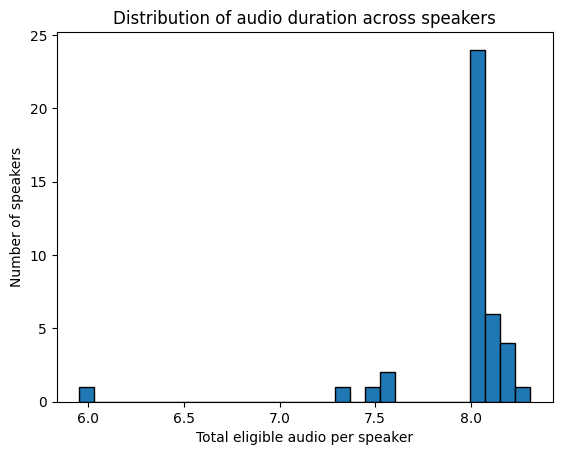

  0th percentile: 5.95 minutes
 10th percentile: 7.57 minutes
 25th percentile: 8.01 minutes
 50th percentile: 8.04 minutes
 75th percentile: 8.10 minutes
 90th percentile: 8.16 minutes
100th percentile: 8.31 minutes


In [27]:
import numpy as np
import matplotlib.pyplot as plt

speaker_minutes = np.array([
    seconds / 60
    for seconds in speaker_seconds.values()
])

if speaker_minutes.size == 0:
    raise ValueError("No eligible recordings found.")

plt.hist(speaker_minutes, bins=30, edgecolor="black")
plt.xlabel("Total eligible audio per speaker")
plt.ylabel("Number of speakers")
plt.title("Distribution of audio duration across speakers")
plt.show()

for percentile in [0, 10, 25, 50, 75, 90, 100]:
    value = np.percentile(speaker_minutes, percentile)
    print(f"{percentile:>3}th percentile: {value:.2f} minutes")

First, since we want to split on differnt speaker ids, we filter out ineligble speakers (speaks with either too much content or too little). Honestly I don't a big problem at all with the duration. I do want to filter out recordings that are too short or too long though

In [28]:
MIN_SECONDS = 0.128  # 2048 samples at 16 kHz
MAX_SECONDS = 30

kept_records = []

for record in records_with_duration:
    info = sf.info(record["path"])
    duration = info.frames / info.samplerate

    if not MIN_SECONDS <= duration <= MAX_SECONDS or not record['reference'].strip():
        continue

    kept_records.append(record)

print( "Retained audio hours:",round(sum(r["duration_seconds"] for r in kept_records) / 3600, 2))

Retained audio hours: 5.31


In [29]:
def split_by_speaker(records, seed=42):
    speakers = sorted({r["speaker_id"] for r in records})

    random.Random(seed).shuffle(speakers)

    n_val = int(0.1 * len(speakers))
    n_test = int(0.1 * len(speakers))

    val_ids = set(speakers[:n_val])
    test_ids = set(speakers[n_val:n_val + n_test])
    train_ids = set(speakers[n_val + n_test:])

    train = [r for r in records if r["speaker_id"] in train_ids]
    val = [r for r in records if r["speaker_id"] in val_ids]
    test = [r for r in records if r["speaker_id"] in test_ids]

    return train, val, test

In [30]:
train, val, test = split_by_speaker(kept_records)

In [31]:
len(train)

2136

In [32]:
len(val)

287

In [33]:
len(test)

271

In [34]:
from torch.utils.data import Dataset, DataLoader


class SpeechDataset(Dataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        audio, sr = librosa.load(record["path"], sr=16000, mono=True)
        clip = torch.tensor(audio, dtype=torch.float32)

        if not 2048 <= clip.numel() <= 480000:
            raise ValueError(f"Unsupported recording length: {record['id']}")
        label = record["reference"]
        return clip, label


In [35]:
train_ds = SpeechDataset(train)
test_ds = SpeechDataset(test)
val_ds = SpeechDataset(val)

train_ds[0]

(tensor([0.0024, 0.0021, 0.0020,  ..., 0.0004, 0.0006, 0.0010]),
 'MISTER QUILTER IS THE APOSTLE OF THE MIDDLE CLASSES AND WE ARE GLAD TO WELCOME HIS GOSPEL')

In [38]:
def collator_fn(items):
    clips = [item[0] for item in items]
    references = [item[1] for item in items]
    return list(clips), list(references)

In [51]:
# now we define a loader to help batch or data i guess?
# see what a laoder needs
train_dataloader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collator_fn)
test_dataloader = DataLoader(test_ds, batch_size=32, shuffle=True, collate_fn=collator_fn)
val_dataloader= DataLoader(val_ds, batch_size=32, shuffle=True, collate_fn=collator_fn)

In [40]:
import math

def prepare_audio_batch(clips, delta, stage2=False):
    # repeat thing and pad to length
    prepared = []
    pairs = []

    for clip in clips:
        clip = clip.to(delta.device)
        length = len(clip)
        numRepeats = length // len(delta) + 1
        delta_effective= delta.repeat(numRepeats)[:length]

        audio_rms = clip.square().mean().sqrt()
        current_rms = delta_effective.square().mean().sqrt()

        target_rms = audio_rms / (10**(23/20))

        if current_rms > target_rms:
            delta_effective = delta_effective * (target_rms/(current_rms+1e-10))

        perturbation = fade(clip + delta_effective)

        pairs.append((fade(clip), fade(delta_effective)))

        padded = F.pad(perturbation, (0, 480000 - perturbation.shape[-1]))
        prepared.append(padded)

    if stage2:
        return torch.stack(prepared), pairs

    return torch.stack(prepared)

def prepared_label_batch(references):

    labels = processor.tokenizer(references, padding=True, return_tensors="pt", return_attention_mask=True).to(device)

    labels = labels["input_ids"].masked_fill(labels.attention_mask.ne(1), -100)

    if (labels[:, 0] == model.config.decoder_start_token_id).all().cpu().item():
        labels = labels[:, 1:]

    return labels

In [48]:
# figure out how the
def model_stage1(data, EPOCHS=100, ALPHA=1e-2):
    delta = torch.zeros(16000, requires_grad=True, dtype=torch.float32, device=next(model.parameters()).device)
    optimizer = torch.optim.Adam([delta], lr=ALPHA)

    for p in model.parameters():
        p.requires_grad = False

    for i in range(EPOCHS):
          for batch_idx, batch in enumerate(data):
                optimizer.zero_grad(set_to_none=True)
                clips, labels = batch
                prepared_audio, prepared_labels = prepare_audio_batch(clips, delta), prepared_label_batch(labels)
                log_spec = compute_log_spec(prepared_audio)
                out = model(log_spec, labels=prepared_labels)
                loss = -out.loss
                if i % 10 == 0:
                    print(f"{loss.item()}")

                loss.backward()

                with torch.no_grad():
                    optimizer.step()
    return delta


In [49]:
def model_stage2(data, delta, EPOCHS=200, ALPHA=1e-3, BETA=1, window_size = 2048):
    history = []
    optimizer = torch.optim.Adam([delta], lr=ALPHA)

    for p in model.parameters():
        p.requires_grad = False
    for i in range(EPOCHS):
          for batch in data:
                optimizer.zero_grad(set_to_none=True)
                clips, labels = batch
                (prepared_audio, pairs), prepared_labels = prepare_audio_batch(clips, delta, stage2=True), prepared_label_batch(labels)
                log_spec = compute_log_spec(prepared_audio)
                out = model(log_spec, labels=prepared_labels)
                masking_losses = []
                for fade_clip, delta_eff in pairs:
                    theta_xs, psd_max = masking.generate_th(fade_clip.detach().cpu().numpy(), 16000, window_size=window_size)
                    psd_max = torch.as_tensor(psd_max, dtype=delta_eff.dtype, device=delta_eff.device)
                    theta_xs = torch.as_tensor(theta_xs, dtype=delta_eff.dtype, device=delta_eff.device)
                    psd_perturb = compute_PSD_for_perturbation(delta_eff, psd_max, window_size)
                    masking_losses.append(compute_mask_threshold_loss(psd_perturb, theta_xs))
                masking_losses = torch.stack(masking_losses)
                loss = -out.loss + BETA * masking_losses.mean()
                loss.backward()
                with torch.no_grad():
                    optimizer.step()
    return delta.detach().clone()

In [52]:
delta_stage1 = model_stage1(train_dataloader, EPOCHS=8)

-2.07438588142395
-2.5011558532714844
-2.268120050430298
-2.396474599838257
-2.1854970455169678
-2.2133054733276367
-2.3840906620025635
-2.28193998336792
-2.285320997238159
-2.6975364685058594
-2.588932752609253
-2.164074420928955
-2.4320178031921387
-2.4407317638397217
-2.6246144771575928
-2.569941997528076
-2.616455554962158
-2.5348610877990723
-3.1253786087036133
-2.8861896991729736
-2.55440092086792
-2.7607669830322266
-3.060960054397583
-2.5982863903045654
-2.8412675857543945
-2.775871753692627
-2.666020631790161
-3.01448655128479
-2.9845829010009766
-2.673436164855957
-2.6717820167541504
-2.8774847984313965
-2.9872241020202637
-2.7833433151245117
-2.9704837799072266
-3.0078859329223633
-3.234593152999878
-2.7729251384735107
-3.066856861114502
-2.805820941925049
-2.886817216873169
-2.7892305850982666
-3.2776498794555664
-3.2880003452301025
-3.1052401065826416
-3.2546567916870117
-3.2358298301696777
-3.2915964126586914
-3.2903449535369873
-3.2599897384643555
-3.3127200603485107
-3.

In [53]:
delta_for_stage2 = delta_stage1.detach().clone().requires_grad_(True)
delta_final = model_stage2(train_dataloader, delta_for_stage2, EPOCHS=8)

validation we just try to apply valiaiton set and then we can see the wer for each of those. is it still batched? idk

In [45]:
def validate(data, delta):
    rows = []
    total_errors = 0.0
    total_words = 0
    model.eval()
    with torch.inference_mode():
        for clips, references in data:
            for clip, reference in zip(clips, references):
                prepared = prepare_audio_batch([clip], delta)
                modified = prepared[0, :clip.numel()]
                transcription, wer = eval(
                    modified, reference, 16000
                )
                word_count = len(custom_normalize(reference).split())
                total_errors += wer * word_count
                total_words += word_count
                rows.append({
                    "reference": reference,
                    "transcription": transcription,
                    "wer": wer,
                })
    corpus_wer = total_errors / total_words if total_words else None
    return rows, corpus_wer

In [60]:
import random
from IPython.display import Audio, display

index = random.randrange(len(val_ds))
clip, reference = val_ds[index]

with torch.inference_mode():
    prepared = prepare_audio_batch([clip], delta_final)
    modified = prepared[0, :clip.numel()].detach().cpu()

# Shared playback scaling avoids clipping without separately
# boosting the volume of either recording.
peak = max(1.0, clip.abs().max().item(), modified.abs().max().item())

print("Reference:", reference)

print("\nOriginal:")
display(Audio(
    (clip / peak).numpy(),
    rate=16000,
    normalize=False,
))

print("\nWith universal perturbation:")
display(Audio(
    (modified / peak).numpy(),
    rate=16000,
    normalize=False,
))

print("\nOriginal transcription:")
_, original_wer = eval(clip, reference, 16000)

print("\nModified transcription:")
_, modified_wer = eval(modified, reference, 16000)

print(f"\nOriginal WER: {original_wer:.1%}")
print(f"Modified WER: {modified_wer:.1%}")

Reference: ALAS HE WALKED WITH NO LESS INDECISION THAN COSETTE

Original:



With universal perturbation:



Original transcription:
he walked with no less indecision than cossett
alas he walked with no less indecision than cosette

Modified transcription:
se você é muito somente é muito somente
alas he walked with no less indecision than cosette

Original WER: 22.2%
Modified WER: 100.0%


In [ ]:
validate(val_dataloader, delta_final)